In [1]:
!pip install torch torchvision torchaudio -q
!pip install torch-geometric -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 36.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 39.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 44.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 21.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 10.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 34.3 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 503.2 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━

In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import glob
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from tqdm import tqdm  # for progress bar

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Image Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 2. Custom Dataset
class MushroomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform
        self.classes = sorted(os.listdir(root_dir))
        for idx, label in enumerate(self.classes):
            for img_path in glob.glob(os.path.join(root_dir, label, "*.jpg")):
                self.images.append(img_path)
                self.labels.append(idx)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]
        if self. transform:
            img = self.transform(img)
        return img, label

dataset = MushroomDataset(root_dir="/kaggle/input/fresh-water-dataset/Original Image", transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# 3. ConvNeXt Feature Extractor
class ConvNeXtFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        self.backbone = nn.Sequential(*list(model.features.children()))

    def forward(self, x):
        return self.backbone(x)  # (B, C, H, W)

convnext_model = ConvNeXtFeatureExtractor().to(device).eval()

# 4. Convert CNN feature map to graph
def image_to_graph(features, label):
    B, C, H, W = features.shape
    graphs = []

    for b in range(B):
        feature_map = features[b]  # (C, H, W)
        x = feature_map.permute(1, 2, 0).reshape(-1, C)  # (H*W, C)

        # Create edges for grid graph
        edges = []
        for i in range(H):
            for j in range(W):
                idx = i * W + j
                if i + 1 < H:
                    edges.append((idx, idx + W))
                    edges.append((idx + W, idx))
                if j + 1 < W:
                    edges.append((idx, idx + 1))
                    edges.append((idx + 1, idx))

        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        y = torch.tensor([label[b]], dtype=torch.long)

        graphs.append(Data(x=x, edge_index=edge_index, y=y))

    return graphs

# 5. GCN Model
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))
        x = torch.mean(x, dim=0)  # Global mean pooling
        return self.fc(x)

gcn_model = GCNClassifier(input_dim=768, output_dim=len(dataset.classes)).to(device)
optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# 6. Training Loop
for epoch in range(10):
    gcn_model.train()
    total_loss = 0

    for img_batch, label_batch in tqdm(dataloader, desc=f"Epoch {epoch+1}"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        with torch.no_grad():
            features = convnext_model(img_batch)

        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            optimizer.zero_grad()
            out = gcn_model(graph)
            loss = criterion(out.unsqueeze(0), graph.y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth
100%|██████████| 109M/109M [00:05<00:00, 22.5MB/s] 
Epoch 1:   6%|▌         | 58/965 [00:46<12:22,  1.22it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 1:  22%|██▏       | 214/965 [02:49<10:38,  1.18it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Epoch 1: 100%|██████████| 965/965 [12:40<00:00,  1.27it/s]


Epoch 1, Loss: 9006.8903


Epoch 2: 100%|██████████| 965/965 [10:13<00:00,  1.57it/s]


Epoch 2, Loss: 2299.8849


Epoch 3: 100%|██████████| 965/965 [10:05<00:00,  1.59it/s]


...

Epoch 8, Loss: 713.9023


Epoch 9: 100%|██████████| 965/965 [10:34<00:00,  1.52it/s]


Epoch 9, Loss: 731.5250


Epoch 10: 100%|██████████| 965/965 [11:02<00:00,  1.46it/s]

Epoch 10, Loss: 705.0194


In [3]:
def evaluate_model(model, convnext_model, dataloader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for img_batch, label_batch in tqdm(dataloader, desc="Evaluating"):
            img_batch = img_batch.to(device)
            label_batch = label_batch.to(device)

            # Feature extraction
            features = convnext_model(img_batch)

            # Convert to graph
            graphs = image_to_graph(features.cpu(), label_batch.cpu())

            for i, graph in enumerate(graphs):
                graph = graph.to(device)
                output = model(graph)
                pred = output.argmax(dim=0)
                if pred.item() == graph.y.item():
                    correct += 1
                total += 1

    accuracy = 100.0 * correct / total
    print(f"Accuracy: {accuracy:.2f}%")

# Call the evaluation function after training
evaluate_model(gcn_model, convnext_model, dataloader)


Evaluating: 100%|██████████| 965/965 [09:32<00:00,  1.69it/s]

Accuracy: 99.83%


In [4]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Store predictions and true labels
all_preds = []
all_labels = []

gcn_model.eval()
with torch.no_grad():
    for img_batch, label_batch in tqdm(dataloader, desc="Evaluating"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        features = convnext_model(img_batch)

        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for i, graph in enumerate(graphs):
            graph = graph.to(device)
            output = gcn_model(graph)
            pred = torch.argmax(output).item()
            true_label = graph.y.item()

            all_preds.append(pred)
            all_labels.append(true_label)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)


Evaluating:   1%|          | 10/965 [00:06<08:45,  1.82it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Evaluating:  91%|█████████ | 877/965 [08:33<00:50,  1.76it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Evaluating: 100%|██████████| 965/965 [09:24<00:00,  1.71it/s]


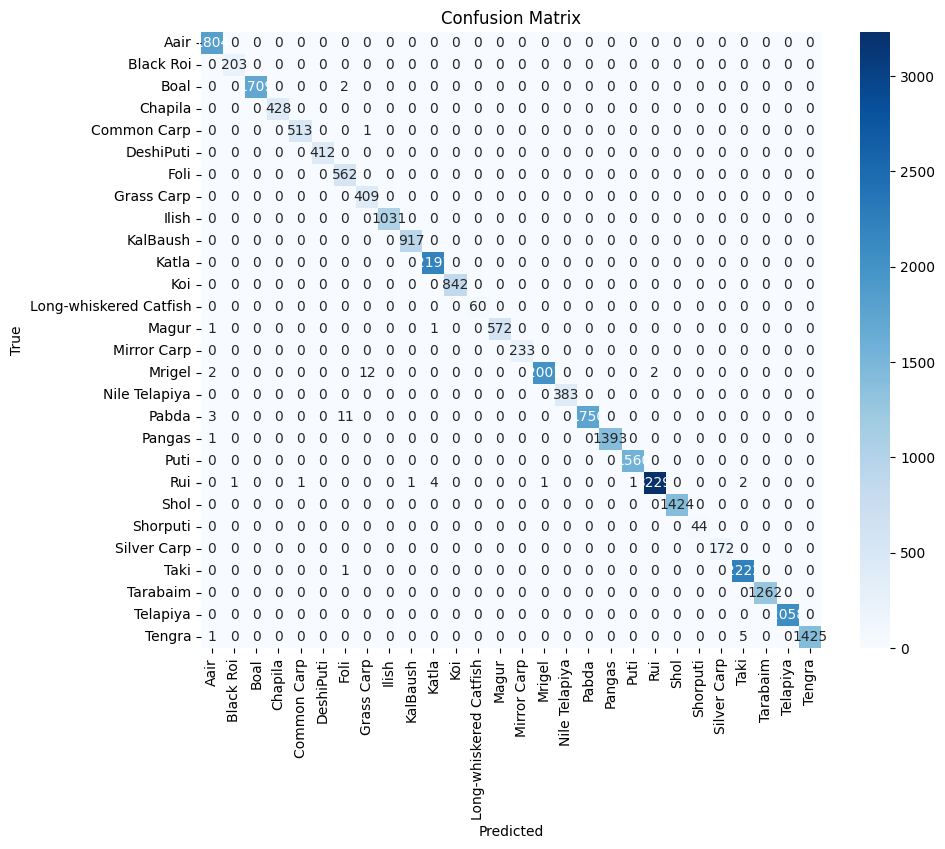

In [5]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=dataset.classes, yticklabels=dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


ROC Eval:   7%|▋         | 63/965 [00:35<07:16,  2.07it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
ROC Eval:  70%|██████▉   | 675/965 [06:39<02:51,  1.69it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
ROC Eval: 100%|██████████| 965/965 [09:38<00:00,  1.67it/s]


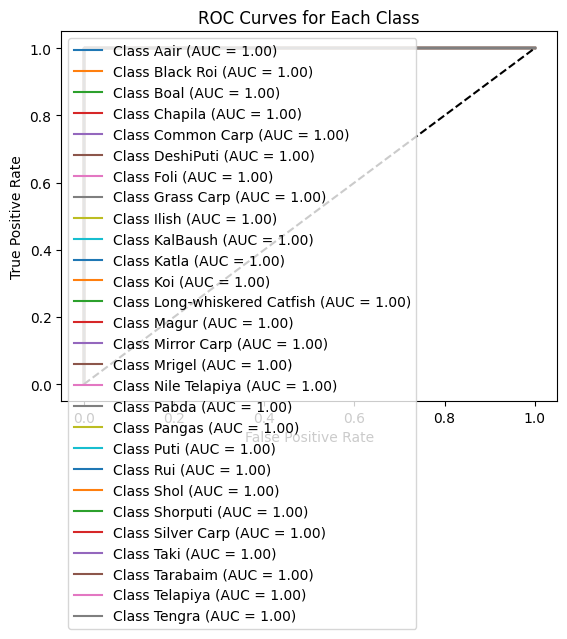

In [6]:
from sklearn.preprocessing import label_binarize

gcn_model.eval()
all_probs = []
all_labels = []

with torch.no_grad():
    for img_batch, label_batch in tqdm(dataloader, desc="ROC Eval"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        features = convnext_model(img_batch)
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for i, graph in enumerate(graphs):
            graph = graph.to(device)
            output = gcn_model(graph)
            prob = F.softmax(output, dim=0).cpu().numpy()
            all_probs.append(prob)
            all_labels.append(graph.y.item())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)
y_true_bin = label_binarize(all_labels, classes=list(range(len(dataset.classes))))

# Compute ROC curve and AUC
for i in range(len(dataset.classes)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    auc = roc_auc_score(y_true_bin[:, i], all_probs[:, i])
    plt.plot(fpr, tpr, label=f"Class {dataset.classes[i]} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Each Class")
plt.legend()
plt.show()


Classification Evaluation:   5%|▌         | 51/965 [00:26<08:16,  1.84it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Classification Evaluation:  99%|█████████▉| 953/965 [08:53<00:06,  1.96it/s]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3442: DecompressionBombWarning: Image size (91438802 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
Classification Evaluation: 100%|██████████| 965/965 [09:00<00:00,  1.78it/s]



✅ Overall Accuracy: 99.83%

📊 Classification Report:
                        precision    recall  f1-score   support

                  Aair       1.00      1.00      1.00      1804
             Black Roi       1.00      1.00      1.00       203
                  Boal       1.00      1.00      1.00      1711
               Chapila       1.00      1.00      1.00       428
           Common Carp       1.00      1.00      1.00       514
             DeshiPuti       1.00      1.00      1.00       412
                  Foli       0.98      1.00      0.99       562
            Grass Carp       0.97      1.00      0.98       409
                 Ilish       1.00      1.00      1.00      1031
              KalBaush       1.00      1.00      1.00       917
                 Katla       1.00      1.00      1.00      2197
                   Koi       1.00      1.00      1.00       842
Long-whiskered Catfish       1.00      1.00      1.00        60
                 Magur       1.00      1.00      

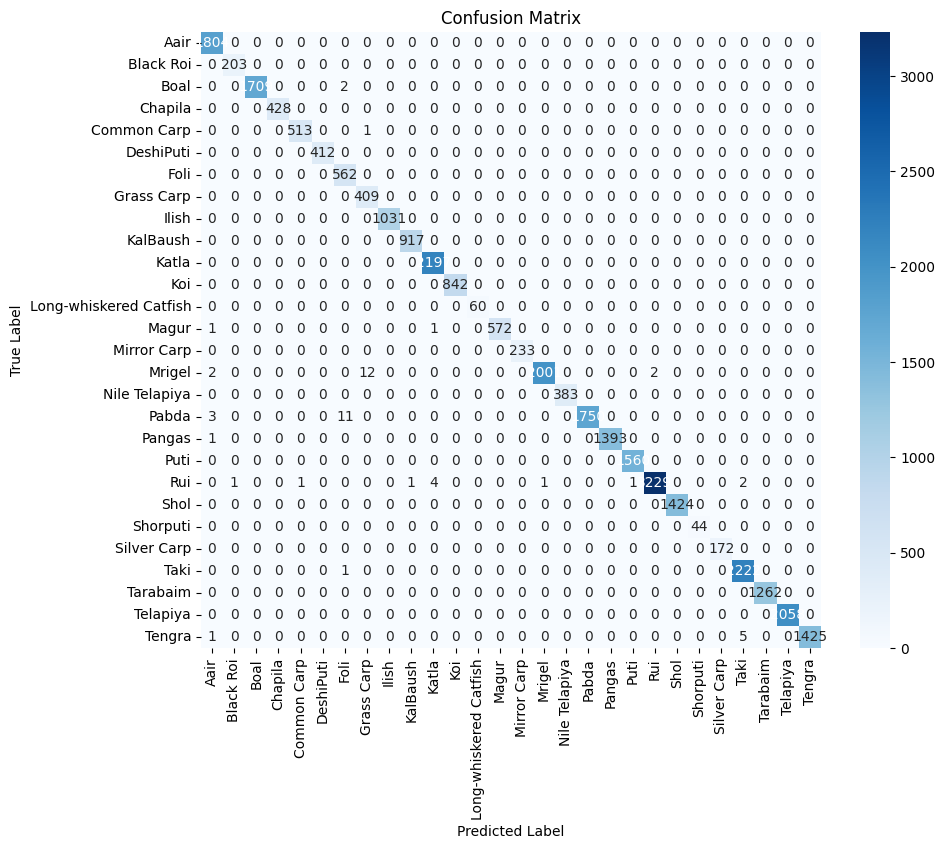

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Switch model to evaluation mode
gcn_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for img_batch, label_batch in tqdm(dataloader, desc="Classification Evaluation"):
        img_batch = img_batch.to(device)
        label_batch = label_batch.to(device)

        # Feature extraction from ConvNeXt
        features = convnext_model(img_batch)

        # Convert feature maps into graphs
        graphs = image_to_graph(features.cpu(), label_batch.cpu())

        for graph in graphs:
            graph = graph.to(device)
            output = gcn_model(graph)

            pred = torch.argmax(output).item()
            label = graph.y.item()

            all_preds.append(pred)
            all_labels.append(label)

# Convert to numpy arrays
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Compute accuracy
accuracy = accuracy_score(all_labels, all_preds)
print(f"\n✅ Overall Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\n📊 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=dataset.classes))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=dataset.classes,
            yticklabels=dataset.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [8]:
!pip install shap


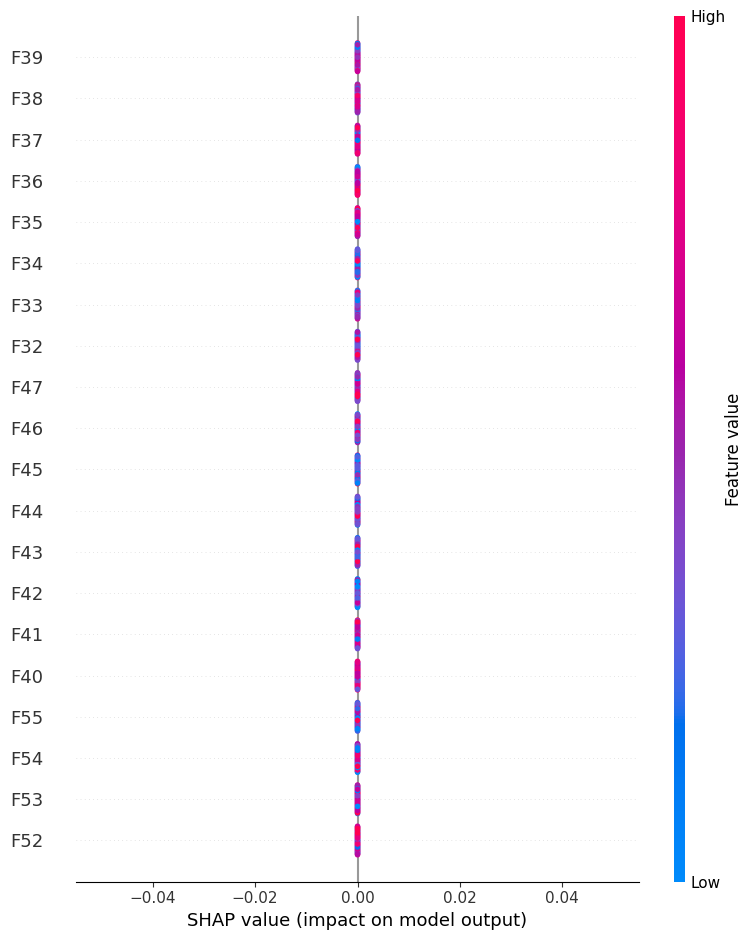

In [11]:
import shap

# Custom wrapper so SHAP works with torch_geometric
class GCNWrapper(nn.Module):
    def __init__(self, model, edge_index):
        super().__init__()
        self.model = model
        self.edge_index = edge_index

    def forward(self, x):
        data = Data(x=x[0], edge_index=self.edge_index)
        out = self.model(data)
        return out.unsqueeze(0)  # Add batch dimension for SHAP

# Choose a graph for explanation
graph = sample_graphs[0].to(device)
wrapped_model = GCNWrapper(gcn_model, graph.edge_index)

# Prepare input for SHAP
background = graph.x.unsqueeze(0).requires_grad_()

# Create SHAP explainer
explainer = shap.GradientExplainer(wrapped_model, background)
shap_values = explainer.shap_values(background)

# Fix the shape mismatch: remove batch dimension
shap_vals = shap_values[0][0]  # (num_nodes, num_features)

# Plot SHAP values
shap.summary_plot(
    shap_vals, 
    graph.x.cpu().numpy(), 
    feature_names=[f"F{i}" for i in range(graph.x.shape[1])]
)


In [13]:
!pip install networkx matplotlib


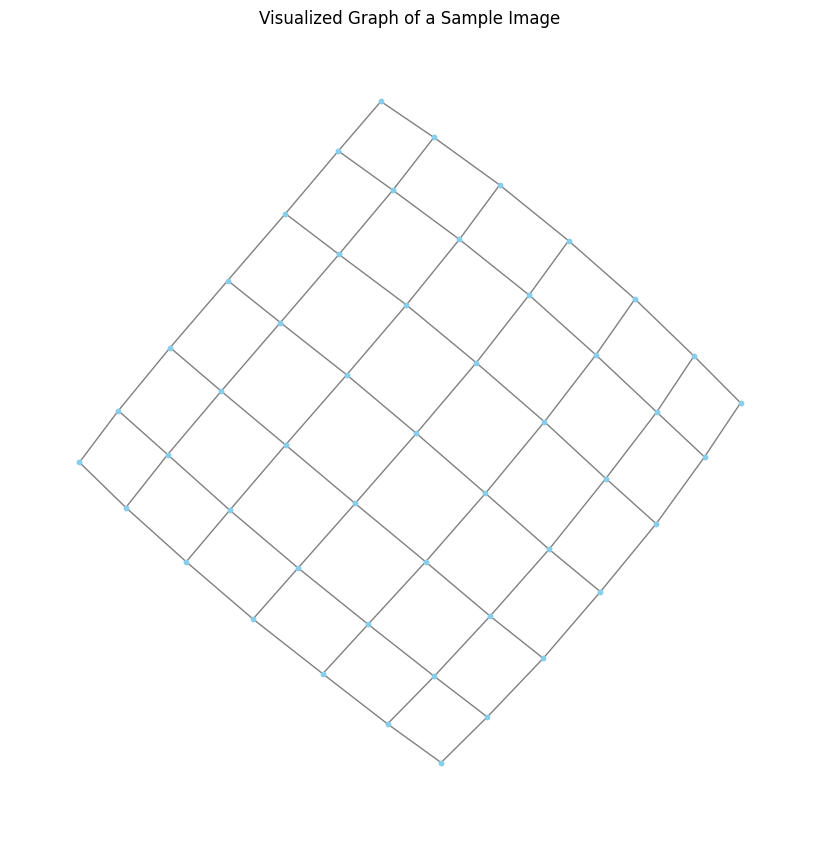

In [14]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx

# Pick one image sample and label from dataset
sample_img, sample_label = dataset[0]  # You can choose any index
sample_img = sample_img.unsqueeze(0).to(device)  # Add batch dimension

# Extract features
with torch.no_grad():
    feature_map = convnext_model(sample_img).cpu()  # shape: (1, C, H, W)

# Convert features to graph
sample_graph = image_to_graph(feature_map, [sample_label])[0]

# Convert torch_geometric Data to networkx graph
nx_graph = to_networkx(sample_graph, to_undirected=True)

# Visualization
plt.figure(figsize=(8, 8))
pos = nx.spring_layout(nx_graph, seed=42)  # Or use nx.kamada_kawai_layout for better spacing
nx.draw(
    nx_graph,
    pos,
    node_size=10,
    node_color='skyblue',
    edge_color='gray',
    with_labels=False
)
plt.title("Visualized Graph of a Sample Image")
plt.show()


Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.


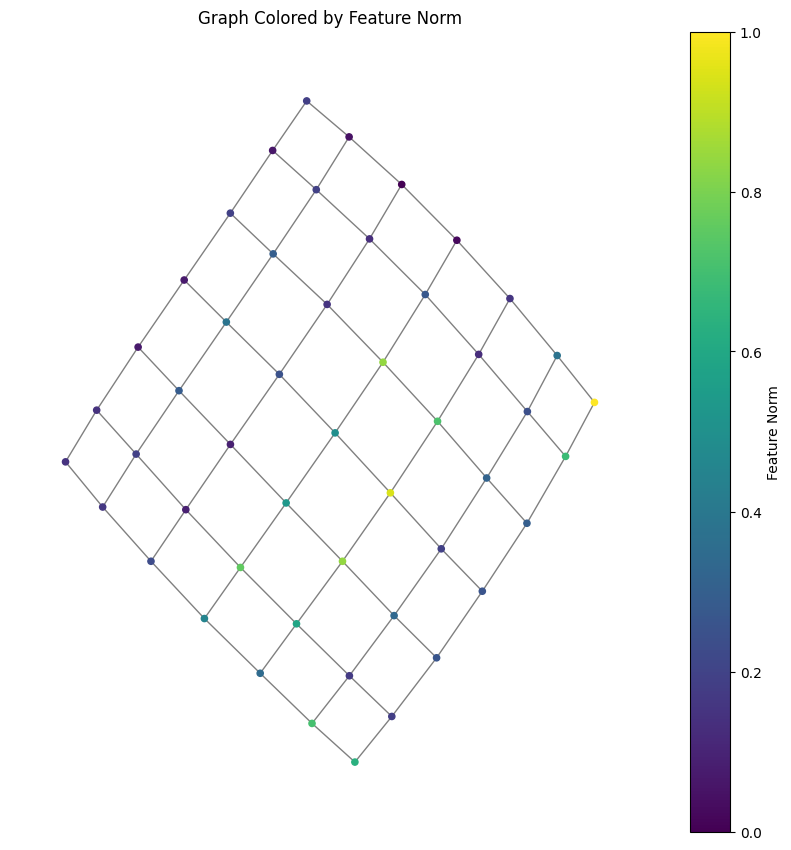

In [15]:
node_values = sample_graph.x.norm(dim=1).numpy()
plt.figure(figsize=(8, 8))
nx.draw(
    nx_graph,
    pos,
    node_size=20,
    node_color=node_values,
    cmap='viridis',
    edge_color='gray',
    with_labels=False
)
plt.title("Graph Colored by Feature Norm")
plt.colorbar(plt.cm.ScalarMappable(cmap='viridis'), label='Feature Norm')
plt.show()


Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.


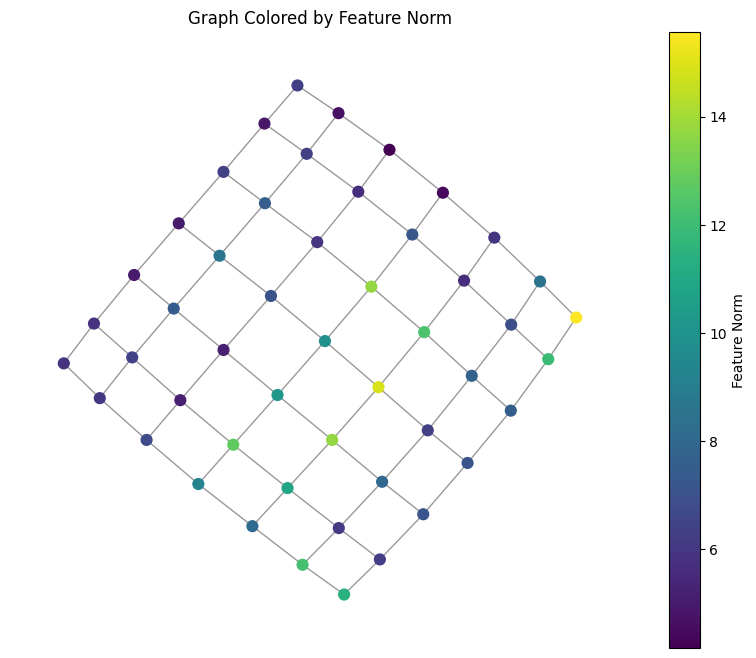

In [16]:
# Get node feature norms as values
node_values = sample_graph.x.norm(dim=1).numpy()

# Plot graph with bigger, visible nodes
plt.figure(figsize=(10, 8))
nodes = nx.draw_networkx_nodes(
    nx_graph, pos,
    node_size=60,
    node_color=node_values,
    cmap='viridis'
)
edges = nx.draw_networkx_edges(nx_graph, pos, alpha=0.4)

# Add colorbar
sm = plt.cm.ScalarMappable(cmap='viridis')
sm.set_array(node_values)
plt.colorbar(sm, label='Feature Norm')

plt.title("Graph Colored by Feature Norm")
plt.axis('off')
plt.show()


In [18]:
print("Number of nodes:", sample_graph.num_nodes)
print("Number of edges:", sample_graph.num_edges)
print("Feature shape:", sample_graph.x.shape)


Number of nodes: 49
Number of edges: 168
Feature shape: torch.Size([49, 768])


In [19]:
print("Feature norms min/max:", sample_graph.x.norm(dim=1).min().item(), sample_graph.x.norm(dim=1).max().item())


Feature norms min/max: 4.166863441467285 15.566213607788086


In [ ]:
class GCNClassifier(nn.Module):
    def __init__(self, input_dim=768, hidden_dim=64, output_dim=10):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, data, return_embedding=False):  # <--- add this argument
        x, edge_index = data.x, data.edge_index
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        x = F.relu(self.conv2(x, edge_index))

        if return_embedding:
            return x  # return node embeddings (num_nodes x hidden_dim)

        x = torch.mean(x, dim=0)  # Global mean pooling
        return self.fc(x)


In [ ]:
import numpy as np

def extract_graph_embeddings(model, dataloader, convnext_model, device):
    model.eval()
    convnext_model.eval()
    embeddings = []
    labels = []

    with torch.no_grad():
        for img_batch, label_batch in dataloader:
            img_batch = img_batch.to(device)
            label_batch = label_batch.to(device)

            features = convnext_model(img_batch).cpu()  # (B, C, H, W)
            graphs = image_to_graph(features, label_batch.cpu())

            for graph in graphs:
                graph = graph.to(device)
                node_emb = model(graph, return_embedding=True)  # (num_nodes, hidden_dim)
                graph_emb = node_emb.mean(dim=0).cpu().numpy()  # global mean pooling to get graph embedding
                embeddings.append(graph_emb)
                labels.append(graph.y.item())

    return np.array(embeddings), np.array(labels)


In [31]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def visualize_embeddings(embeddings, labels, method='tsne'):
    if method == 'tsne':
        reducer = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
    elif method == 'pca':
        reducer = PCA(n_components=2)
    else:
        raise ValueError("Method must be 'tsne' or 'pca'")

    reduced = reducer.fit_transform(embeddings)

    plt.figure(figsize=(8,6))
    scatter = plt.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap='tab10', alpha=0.8)
    plt.colorbar(scatter, ticks=range(len(set(labels))))
    plt.title(f"Graph Embeddings Visualized using {method.upper()}")
    plt.xlabel('Component 1')
    plt.ylabel('Component 2')
    plt.grid(True)
    plt.show()
